# Exercício

Considere o sinal periódico:

$$
v(t) = 10 \cdot \sin(10t)
$$

e a seguinte grandeza definida por:

$$
I = \int_{0}^{3T} v(t)\,dt
$$

onde $T$ é o período fundamental de $v(t)$.

---

## Pede-se:

1. Determinar o período $T$ do sinal.

2. Calcular o valor da integral $I$.

3. Determinar o **valor médio** de $I$ no intervalo considerado.

4. Determinar o **valor eficaz (RMS)** de $I$ no intervalo considerado.

In [ ]:
# bibliotecas
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Cálculo da Integral
def integral_trapezios(x, y):
    quantidade = len(x)
    dx = x[1]-x[0]

    somatorio = 0
    for ii in range(0, quantidade, 1):
        if ii==0 or ii==quantidade-1:
            somatorio = somatorio + y[ii]
        else:
            somatorio = somatorio + 2*y[ii]

    integral = dx/2 * somatorio

    return integral

In [ ]:
# Cálculo do Valor Médio
def valor_medio(x, y):
    periodo = x[-1] - x[0]
    integral = integral_trapezios(x, y)
    medio = (1/periodo) * integral
    return medio

In [ ]:
# Cálculo do Valor Eficaz
def valor_eficaz(x, y):
    periodo = x[-1] - x[0]
    integral = integral_trapezios(x, y**2)
    eficaz = np.sqrt((1/periodo)*integral)
    return eficaz


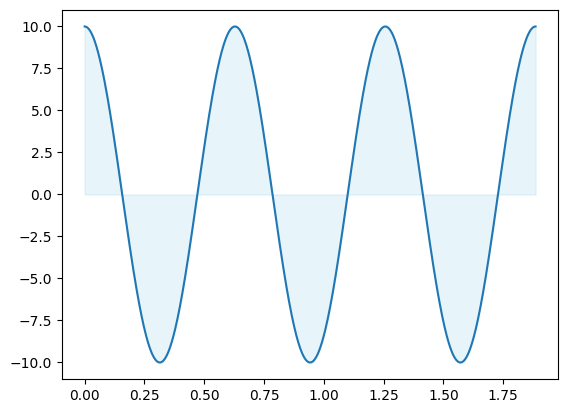

In [ ]:
omega = 10
T = (2*np.pi) / omega

tempo = np.linspace(0, 3*T, 1000)
tensao = 10 * np.cos(omega*tempo)

plt.plot(tempo, tensao)
plt.fill_between(tempo, tensao, color='skyblue', alpha=0.2, label='Área sob a curva')



In [ ]:
valor_medio_da_funcao = round(valor_medio(tempo, tensao), 4)
print(f"A médio da função vale {valor_medio_da_funcao}")

valor_eficaz_da_funcao = round(valor_eficaz(tempo, tensao), 4)
print(f"A eficaz da função vale {valor_eficaz_da_funcao}")

A médio da função vale -0.0
A eficaz da função vale 7.0711


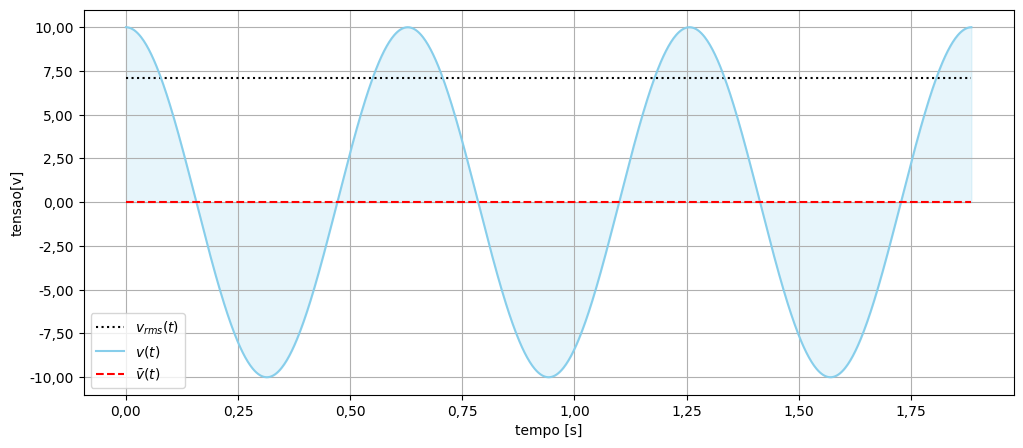

In [ ]:
plt.figure(figsize=(12, 5))  # largura maior (12), altura (5)
linha_do_medio = valor_medio_da_funcao * np.ones(len(tempo))
linha_do_eficaz = valor_eficaz_da_funcao * np.ones(len(tempo))
plt.plot(tempo,linha_do_eficaz,color='black',label=r'$v_{rms}(t)$',ls='dotted')
plt.plot(tempo, tensao, color='skyblue', label='$v(t)$')
plt.fill_between(tempo, tensao, color='skyblue', alpha=0.2)
plt.plot(tempo, linha_do_medio, color='red', ls='dashed', label=r'$\bar{v}(t)$')
plt.legend()
plt.xlabel('tempo [s]')
plt.ylabel('tensao[v]')
plt.grid(":")

from matplotlib.ticker import FuncFormatter

def virgula(x, pos):
    return f'{x:.2f}'.replace('.', ',')

plt.gca().xaxis.set_major_formatter(FuncFormatter(virgula))
plt.gca().yaxis.set_major_formatter(FuncFormatter(virgula))